# The fix-first decision on Zomato Gold: what is fixed first?

**Week 4, Thursday, SECTION 9, the fourth case notebook (L5 and L6).** It applies The fix-first
decision and its evidence, which notebook 08 taught on the invented college, to the two
problems notebooks 06 and 07 found on Zomato Gold. The dashboard's flat 38 percent has not yet
counted the 13,000-member August cohort, whose 8,027 sale-week members kept 20 percent in month
one against 49 for the organic August members. On the order flow, members on Android who start
checkout now complete the order 55 percent of the time against 72.5 before the release. One
engineering team can take one problem first, and this notebook computes the page that says
which, from the same frames notebooks 06 and 07 use.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for
> this class.*

**The ticket. Zomato Gold, Chennai, the membership and the app's order flow.** Zomato Gold is the
food-delivery app's paid membership, whose members get free delivery (Zomato's shareholder letter of
19 May 2023, checked 12 October 2026). The membership dashboard reports month-two retention for
Chennai, the share of members two or more months past their signup month who ordered in the month,
as flat at 38 percent for June, July, August and September 2026. A member who places no order in a
month is not retained that month; she is still a member and may order again. A **cohort** is the
members who joined in the same month. Each cohort's own curve falls with age, and each cohort's
month-one rate is lower than the one before: January 58 percent, April 53, July 49, and August 31.
The August cohort, 13,000 members, 2.6 times the 5,000 a month of January to July, grew out of a
sale week with a discounted first month. On Monday 14 September 2026 a new checkout flow shipped on
Android; since then members' add-to-cart to order conversion on Android fell from 58 to 44 percent,
while members on iOS went from 57 to 56 and non-members on Android from 52 to 51. **The ask, due
Friday:** is it a cohort problem (members who joined in some months order less than members who
joined in others) or an everyone problem (members of every signup month changed at once), which
funnel stage owns the loss, and what should be fixed first, with the evidence.

**Who needs the answer.** The membership lead, who takes one call to Friday's review, and the app
team's lead, who will say the checkout is fine. A call without its cost cannot be weighed, and a
call without its objection answered does not survive the meeting.

**The questions on the way.**

1. Which problem moved, for whom, and since when?
2. How big is the order loss, counted two ways, and what is it worth?
3. What answers the app team's lead?
4. What would change the order of work?
5. What does the page say, line by line?

In [1]:
# Load the members, their months and the event log, the frames notebooks 06 and 07 use.
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)

members = pd.read_csv("../data/C2_W04_D04_members_STUDENT.csv")
mm = pd.read_csv("../data/C2_W04_D04_member_months_STUDENT.csv").merge(
    members[["member_id", "cohort_month", "signup_channel"]], on="member_id")
mm["age"] = (mm["month"].str[:4].astype(int) * 12 + mm["month"].str[5:].astype(int)
             - mm["cohort_month"].str[:4].astype(int) * 12 - mm["cohort_month"].str[5:].astype(int))
ev = pd.read_csv("../data/C2_W04_D04_events_STUDENT.csv.gz", parse_dates=["event_ts"])
ev["side"] = (ev["event_ts"] >= "2026-09-14").map({False: "before", True: "after"})
# Count member orders twice: in the order records, and in the app's event log.
placed = ev[ev["is_member"] & (ev["stage"] == "order_placed")]
from_events = placed.groupby(placed["event_ts"].dt.strftime("%Y-%m")).size()
from_records = mm[mm["month"].isin(["2026-08", "2026-09"])].groupby("month")["orders"].sum()
print(pd.DataFrame({"order records": from_records, "event log": from_events}))
check("the order records and the event log count the same member orders in August and September",
      from_records.to_dict() == from_events.to_dict())

         order records  event log
2026-08          33699      33699
2026-09          27212      27212
PASS  the order records and the event log count the same member orders in August and September


## Which problem moved, for whom, and since when?

The page starts where notebook 08 started on the college: a problem goes first when its step moved
against its own past, and the evidence names the group and the date. **Predict before you run.**
Which of Gold's two problems goes first?

- a) The sale-week members, since 8,027 people outnumber a weekly order loss
- b) Both at once, split across two teams, so that neither problem waits
- c) Neither, until October's dashboard shows how far retention falls
- d) The checkout: it moved, it loses orders every week, and a fix ends it

The next cell builds the evidence table: each group's two steps inside the checkout, before and
after 14 September, so the step that moved and the comparators that held sit side by side.

In [2]:
# The evidence table: each group's two steps inside the checkout, before and after the release.
flow = ev[ev["stage"].isin(["add_to_cart", "checkout_start", "order_placed"])]
n = flow.groupby(["is_member", "platform", "side", "stage"]).size().unstack()
start = (n["checkout_start"] / n["add_to_cart"]).unstack()[["before", "after"]]
finish = (n["order_placed"] / n["checkout_start"]).unstack()[["before", "after"]]
GROUPS = {(True, "android"): "members on Android", (True, "ios"): "members on iOS",
          (False, "android"): "non-members on Android"}
evidence = pd.DataFrame({name: {"cart to checkout start, before": start.loc[g, "before"],
                                "cart to checkout start, after": start.loc[g, "after"],
                                "checkout start to order, before": finish.loc[g, "before"],
                                "checkout start to order, after": finish.loc[g, "after"]}
                         for g, name in GROUPS.items()})
print((100 * evidence).round(1).to_string())
moved = (100 * (finish["before"] - finish["after"])).abs()
check("members on Android: checkout start to order 72.5 to 55, while starting checkout held at 80",
      [round(100 * v, 1) for v in finish.loc[(True, "android")]] == [72.5, 55.0]
      and [round(100 * v) for v in start.loc[(True, "android")]] == [80, 80])
check("on the same step, iOS members and non-members on Android move by under 1.5 points",
      moved.loc[(True, "ios")] < 1.5 and moved.loc[(False, "android")] < 1.5)

                                 members on Android  members on iOS  non-members on Android
cart to checkout start, before                 80.0            80.0                    80.0
cart to checkout start, after                  80.0            80.0                    80.0
checkout start to order, before                72.5            71.3                    65.0
checkout start to order, after                 55.0            70.0                    63.7
PASS  members on Android: checkout start to order 72.5 to 55, while starting checkout held at 80
PASS  on the same step, iOS members and non-members on Android move by under 1.5 points


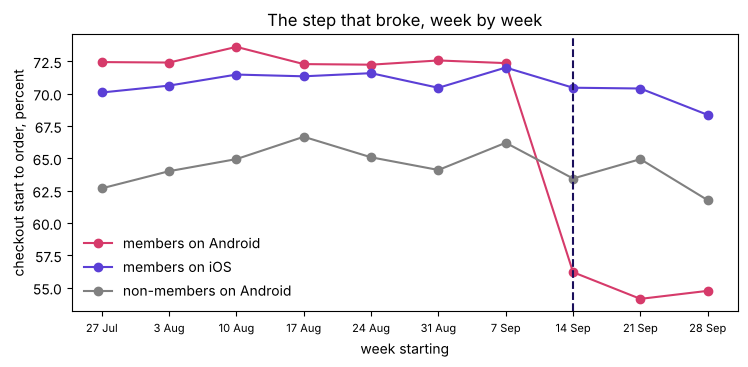

week
2026-07-27    72.4
2026-08-03    72.4
2026-08-10    73.6
2026-08-17    72.3
2026-08-24    72.2
2026-08-31    72.6
2026-09-07    72.4
2026-09-14    56.2
2026-09-21    54.1
2026-09-28    54.8
the lowest week before the release: 72.2; the first week five points under it: 14 September
PASS  the step breaks in the week of the release, Monday 14 September


In [3]:
# Week by week, checkout start to order for each group, the release marked; then the week it breaks.
weekly_flow = flow.assign(week=flow["event_ts"].dt.to_period("W-SUN").dt.start_time)
fig, ax = plt.subplots(figsize=(8.6, 3.6))
for g, colour in [((True, "android"), "#D63A6A"), ((True, "ios"), "#5B3FD6"), ((False, "android"), "grey")]:
    w = weekly_flow[(weekly_flow["is_member"] == g[0]) & (weekly_flow["platform"] == g[1])]
    w = w.groupby(["week", "stage"]).size().unstack()
    ax.plot(w.index, 100 * w["order_placed"] / w["checkout_start"], marker="o", color=colour, label=GROUPS[g])
ax.set_xticks(w.index, [f"{d.day} {d:%b}" for d in w.index], fontsize=8)
ax.axvline(pd.Timestamp("2026-09-14"), ls="--", color="#1A0F5C"); ax.legend(frameon=False, loc="lower left")
ax.set_xlabel("week starting"); ax.set_ylabel("checkout start to order, percent")
ax.set_title("The step that broke, week by week"); plt.show()
w = weekly_flow[weekly_flow["is_member"] & (weekly_flow["platform"] == "android")]
w = w.groupby(["week", "stage"]).size().unstack()
weekly = 100 * w["order_placed"] / w["checkout_start"]
before_low = weekly[weekly.index < "2026-09-14"].min()
first_low = weekly[weekly < before_low - 5].index.min()
print(weekly.round(1).to_string())
print(f"the lowest week before the release: {before_low:.1f}; the first week five points under it: {first_low:%d %B}")
check("the step breaks in the week of the release, Monday 14 September", first_low == pd.Timestamp("2026-09-14"))

**What happened.** The answer is d. Starting checkout held at 80 percent of carts for members on
Android. Completing the order once checkout had started fell from 72.5 to 55 percent, and the
weekly line sits near 72.5 for seven weeks and breaks in the week of 14 September. On the same
step, members on iOS went from 71 to 70 and non-members on Android from 65 to 64, and they met
the same release, so the comparators place the fall in one group and the date ties it to the
release. The sale-week members' weak month one is the other problem, and it is already spent:
what can still change there is whether the next sale runs.

## How big is the order loss, counted two ways, and what is it worth?

**The plausible wrong answer.** "1,317 orders a week, every week, so Rs 6.6 lakh is the loss." The
decision it would mislead: a cost line no finance office accepts, since it assumes no failed
cart ever came back as a later order and prices every order at the top of the range. The next
cell counts the loss two ways, from the carts and in orders placed against each comparator's own
change, and prices the range at an assumed Rs 300 to Rs 500 an order.

from the carts, if no failed cart came back: 0.14 x 22,841 carts over 17 days = 1,317 orders a week
counted in orders placed, against iOS members: 1,266 orders a week
counted in orders placed, against non-members on Android: 1,133 orders a week
order value at Rs 300 to Rs 500 an order (an assumption): Rs 3.4 to 6.6 lakh a week
PASS  about 1,317 orders a week from the carts, and 1,133 to 1,266 counted in orders placed
PASS  Rs 3.4 to 6.6 lakh of order value a week


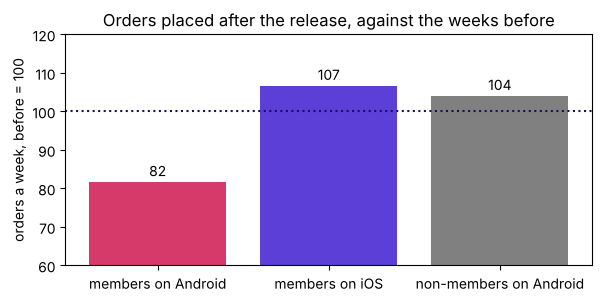

In [4]:
# The loss two ways: from the carts, and in orders placed against each comparator; then the rupees.
cart_rate = (n["order_placed"] / n["add_to_cart"]).unstack()[["before", "after"]]
drop = cart_rate.loc[(True, "android"), "before"] - cart_rate.loc[(True, "android"), "after"]
carts_after = n.loc[(True, "android", "after"), "add_to_cart"]
from_carts = drop * carts_after / 17 * 7                              # 17 days after the release
orders = ev[ev["stage"] == "order_placed"].groupby(["is_member", "platform", "side"]).size().unstack()
per_week = pd.DataFrame({"before": orders["before"] / 44 * 7, "after": orders["after"] / 17 * 7})
change = per_week["after"] / per_week["before"] - 1                   # each group against its own past
android = per_week.loc[(True, "android")]
placed_loss = {name: android["before"] * (1 + change.loc[g]) - android["after"]
               for g, name in [((True, "ios"), "against iOS members"),
                               ((False, "android"), "against non-members on Android")]}
print(f"from the carts, if no failed cart came back: {drop:.2f} x {carts_after:,} carts over 17 days "
      f"= {from_carts:,.0f} orders a week")
for name, v in placed_loss.items():
    print(f"counted in orders placed, {name}: {v:,.0f} orders a week")
low, high = min(placed_loss.values()), from_carts
print(f"order value at Rs 300 to Rs 500 an order (an assumption): Rs {low * 300 / 1e5:.1f} to "
      f"{high * 500 / 1e5:.1f} lakh a week")
check("about 1,317 orders a week from the carts, and 1,133 to 1,266 counted in orders placed",
      round(from_carts) == 1317 and sorted(round(v) for v in placed_loss.values()) == [1133, 1266])
check("Rs 3.4 to 6.6 lakh of order value a week",
      (round(low * 300 / 1e5, 1), round(high * 500 / 1e5, 1)) == (3.4, 6.6))
fig, ax = plt.subplots(figsize=(6.8, 3.0))
index = 100 * (1 + change.loc[list(GROUPS)])
ax.bar([GROUPS[g] for g in GROUPS], index.values, color=["#D63A6A", "#5B3FD6", "grey"])
for i, v in enumerate(index.values):
    ax.text(i, v + 1.5, f"{v:.0f}", ha="center")
ax.axhline(100, ls=":", color="#1A0F5C"); ax.set_ylim(60, 120)
ax.set_ylabel("orders a week, before = 100"); ax.set_title("Orders placed after the release, against the weeks before")
plt.show()

**What happened.** From the carts, about 1,317 orders a week, which assumes no failed cart came
back. Counted in orders placed, which keeps the ones that did, Android members' weekly orders
fell 18 percent while iOS members' rose 7 and non-members' on Android 4: held to either
comparator's change, the loss is 1,266 or 1,133 orders a week, about a quarter of the 5,064 a
week Android members placed before the release. The range on the page is 1,133 to 1,317 orders
a week, Rs 3.4 to 6.6 lakh of order value, of which Zomato keeps its commission and fees.

## What answers the app team's lead?

The app team's lead says carts that start checkout held at 80 percent on every platform, so the
new flow works. The evidence table above says the first half is true. Concede it, restate the
question, and bring the step after it: completion fell for members on Android only, so the
place to look is something in the new flow that only members see.

## What would change the order of work?

The page's last line names the fact that would put the sale-week members first: most members who
failed at checkout coming back and ordering later, so that the release cost a delay rather than
orders. **Predict before you run.** After a checkout with no order, how often did an Android
member order within a day, before the release and after it?

- a) Far more often after, so most of the loss is only a delay
- b) About as often as before, while the failures nearly doubled
- c) Never, in either stretch
- d) The event log cannot say, since a failed checkout leaves no row

        share  failed  came_back  failed a week  came back a week
t                                                                
before  0.365   12074       4404       1920.864           700.636
after   0.351    8223       2887       3385.941          1188.765


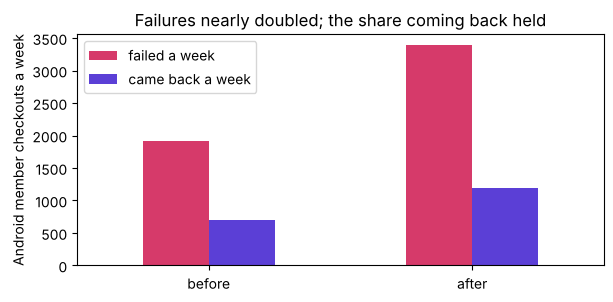

PASS  the share of failed checkouts followed by an order within a day did not rise, so most lost orders stay lost


In [5]:
# After a checkout with no order, how often an Android member ordered within a day, before and after.
a = ev[ev["is_member"] & (ev["platform"] == "android")]
s = a.groupby("session_id").agg(user_id=("user_id", "first"), t=("event_ts", "min"))
s = s.join(a.pivot_table(index="session_id", columns="stage", values="user_id", aggfunc="size", fill_value=0).gt(0))
failed = s[s["checkout_start"] & ~s["order_placed"]].sort_values("t")
later = s[s["order_placed"]].sort_values("t")[["user_id", "t"]].rename(columns={"t": "next_order"})
nxt = pd.merge_asof(failed, later, left_on="t", right_on="next_order", by="user_id",
                    direction="forward", allow_exact_matches=False)     # each failure's next order
nxt["within_a_day"] = (nxt["next_order"] - nxt["t"]) <= pd.Timedelta(days=1)
side = (nxt["t"] >= "2026-09-14").map({False: "before", True: "after"})
retry = nxt.groupby(side)["within_a_day"].agg(share="mean", failed="size", came_back="sum").loc[["before", "after"]]
retry["failed a week"] = retry["failed"] / [44, 17] * 7
retry["came back a week"] = retry["came_back"] / [44, 17] * 7
print(retry.round(3).to_string())
fig, ax = plt.subplots(figsize=(6.8, 3.0))
retry[["failed a week", "came back a week"]].plot.bar(ax=ax, rot=0, color=["#D63A6A", "#5B3FD6"])
ax.set_xlabel(""); ax.set_ylabel("Android member checkouts a week")
ax.set_title("Failures nearly doubled; the share coming back held"); plt.show()
check("the share of failed checkouts followed by an order within a day did not rise, so most lost orders stay lost",
      retry.loc["after", "share"] <= retry.loc["before", "share"])

**What happened.** The answer is b. Before the release, 36.5 percent of failed checkouts were
followed by an order within a day; after it, 35.1 percent. Failures nearly doubled, from 1,921 to
3,386 a week, so more members came back in number, 1,189 a week against 701, which is why the
page's lower bound is counted in orders placed. Most failed orders stayed lost, so the order of
work holds: the checkout first.

## Your turn: what does the sale-week members' payback rest on?

Another sale is the wrong fix for the dashboard: its cohort enters the count at month two and,
if it behaves like this one, pulls the number down again at the discount's cost. Whether this
sale paid back is open. **Your turn.** In the empty cell, take the August cohort at month one,
group it by `signup_channel`, and compute each group's members, its share active and its orders
each; then say what you would set beside the gap before calling the sale paid back.

```python
aug = mm[(mm["cohort_month"] == "2026-08") & (mm["age"] == 1)]
aug.groupby("signup_channel")["orders"].agg(["size", "mean"])
```

**Check your cell against this one.** It computes the August cohort's month one by channel, then
prints the page's five lines from the numbers this notebook computed.

In [6]:
# The August cohort's month one by channel; then the five-line page, every number computed above.
aug = mm[(mm["cohort_month"] == "2026-08") & (mm["age"] == 1)]
pay = aug.groupby("signup_channel")["orders"].agg(members="size", active=lambda o: (o > 0).mean(), orders_each="mean")
print(pay.round(2).to_string())
check("in month one the sale-week members placed 0.23 orders each and the organic August members 0.61",
      [round(pay.loc[c, "orders_each"], 2) for c in ("sale", "organic")] == [0.23, 0.61])
f = 100 * finish
page = [
    "The call. Fix the member path of the new Android checkout first; until the fix ships, switch Android "
    "members back to the old checkout, or give half of them the old path for two days to confirm the cause.",
    f"The evidence. Checkout start to order fell from {f.loc[(True, 'android'), 'before']:.1f} to "
    f"{f.loc[(True, 'android'), 'after']:.1f} percent for members on Android from the week of {first_low:%d %B}; "
    f"starting checkout held at {100 * start.loc[(True, 'android'), 'after']:.0f}; on the same step members on iOS "
    f"went from {f.loc[(True, 'ios'), 'before']:.0f} to {f.loc[(True, 'ios'), 'after']:.0f} and non-members on "
    f"Android from {f.loc[(False, 'android'), 'before']:.0f} to {f.loc[(False, 'android'), 'after']:.0f}; the order "
    f"records match the event log.",
    f"The cost. About {round(low):,} to {round(high):,} orders a week, Rs {low * 300 / 1e5:.1f} to "
    f"{high * 500 / 1e5:.1f} lakh of order value at Rs 300 to Rs 500 an order, an assumption.",
    "The objection. The app team's lead is right that starting checkout held; the step after it broke, and "
    "only for members on Android, so the place to look is what only members see.",
    f"What would change it. Most failed checkouts coming back as orders; {100 * retry.loc['before', 'share']:.1f} "
    f"percent came back within a day before the release and {100 * retry.loc['after', 'share']:.1f} after, so most "
    f"did not. The sale-week members, at {pay.loc['sale', 'orders_each']:.2f} orders each in month one against "
    f"{pay.loc['organic', 'orders_each']:.2f}, wait for the payback question.",
]
print("\n".join(f"{i}. {line}" for i, line in enumerate(page, 1)))

                members  active  orders_each
signup_channel                              
organic            4973    0.49         0.61
sale               8027    0.20         0.23
PASS  in month one the sale-week members placed 0.23 orders each and the organic August members 0.61
1. The call. Fix the member path of the new Android checkout first; until the fix ships, switch Android members back to the old checkout, or give half of them the old path for two days to confirm the cause.
2. The evidence. Checkout start to order fell from 72.5 to 55.0 percent for members on Android from the week of 14 September; starting checkout held at 80; on the same step members on iOS went from 71 to 70 and non-members on Android from 65 to 64; the order records match the event log.
3. The cost. About 1,133 to 1,317 orders a week, Rs 3.4 to 6.6 lakh of order value at Rs 300 to Rs 500 an order, an assumption.
4. The objection. The app team's lead is right that starting checkout held; the step after it br

**The questions, answered.** (1) The checkout's last step moved, for members on Android, from the
week of 14 September, 72.5 to 55 percent, while members on iOS and non-members on Android held
on the same step; the sale-week members' month one, 20 percent against 49, is already spent. (2)
About 1,317 orders a week from the carts, 1,133 to 1,266 counted in orders placed, Rs 3.4 to 6.6
lakh of order value at an assumed Rs 300 to Rs 500 an order. (3) Concede that starting checkout
held at 80, then bring the step after it. (4) Most failed checkouts coming back as orders would
change the order, and they did not. (5) The five lines above, each with its number. A sale-week
member placed 0.23 orders in month one against 0.61 for an organic member; whether the sale paid
back waits until the discount and the margin sit beside those orders.

**What comes next.** SECTION 9 closes by walking the same call as an interview answer (S78 to
S81) and recalling the day's five topics in the Kahoot. In the lab, notebook 10 runs the five
topics on Kalpa Retail's Retail-Plus tier.